In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import scipy 
from plotting_helper import *
%matplotlib inline

figures_path = 'figures/'
palette = plt.rcParams['axes.prop_cycle'].by_key()['color']  

In [2]:
def TASEP_assump(parameters, state_var, dt , elong_fun):

    
    x_vec = state_var[0]   #free mRNA concentrations
    xr_vec = state_var[1]  # bound mRNA ribosome concentrations
    y_vec = state_var[2]   #protein concentrations
    r = parameters['R'] - np.sum(xr_vec)  #concentration of free ribosomes, separate pool for each


    new_x_vec = x_vec + dt * (-parameters['α']  * r * x_vec  + parameters['β']* xr_vec - elong_fun(parameters['δ'], xr_vec) * xr_vec)
    new_xr_vec = xr_vec + dt * (parameters['α'] * r *  x_vec - parameters['β'] * xr_vec + elong_fun(parameters['δ'], xr_vec) * xr_vec)
    new_y_vec = y_vec + dt * (parameters['β']  * xr_vec - parameters['γ'] * y_vec)
    #reinitiation

    return new_x_vec, new_xr_vec, new_y_vec


def simulation_wrapper(state0, params, update,elong_f, sim_time, dt): 
    
    states = np.zeros([int(sim_time/dt)+1, state0.shape[0], state0.shape[1]])
    states[0] = state0
    
    for t in range(int(sim_time/dt)): 
        states[t+1] = update(params, states[t], dt, elong_f)
        
    return states[1:]

Redo a model without explicit competition but with ribosome loading dependent elongation rate (stiffness) to see whether the results from Fernandes et al (2017) can be qualitatively reproduced by a differential equation model

Keeping in mind that length-dependent intiation rates might be another way to go about this. 

Key assumtions: Ribosomes have individual pool, no protein resources e.g. aminoacids. 

In [3]:
#set parameters: 
rng = np.random.RandomState(seed = 5)
γ = 0.05
β = 0.1
α = 0.01
δ = 0.05
x_init = 1
sim_time = 100 #should be enough
dt = 0.001
N = 2
l = np.array([1,10])
Y = N*2
Rs = np.linspace(0.001,10,50)
Ys = 1 #1 for each, can see if this in any way infleunces the results (should do the total but not relative)

x0 = np.ones([N])*x_init
init_state =np.array([x0, np.zeros([N]),np.zeros([N])]) 

def β_static(β, n_trans): 
    return β

def β_nonlin(β, n_trans): 
    return β * ((1+np.exp(-n_trans)))

def β_ceiled(β, n_trans): 
    smaller = 0.01 > (1-n_trans)
    factor = 0.01 * smaller + (1-n_trans) * (smaller == 0)
    return β * factor



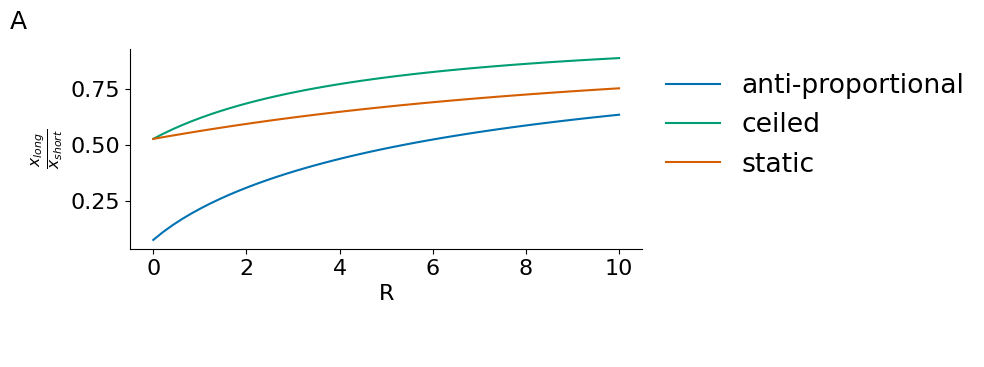

In [4]:
ys_bs = np.zeros([Rs.shape[0], N])
ys_lr = np.zeros([Rs.shape[0], N])
ys_sr = np.zeros([Rs.shape[0], N])

parameters = dict()
parameters['β'] = β
parameters['α'] = α  #so initiation is the rate limiting step
parameters['δ'] = δ/l
parameters['γ'] = γ
parameters['l'] = l
parameters['Y_max'] = Ys


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]

    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_nonlin, sim_time, dt) 
    ys_bs[r,:]= res[-1,1,:]#res[-1,2,:]

    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_ceiled, sim_time, dt) 
    ys_lr[r,:]= res[-1,1,:]#res[-1,2,:]
    
    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_static, sim_time, dt) 
    ys_sr[r,:]= res[-1,1,:]#res[-1,2,:]

        
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, ys_bs[:,1]/ys_bs[:,0], label = 'anti-proportional', color = palette[0])
ax.plot(Rs, ys_lr[:,1]/ys_lr[:,0], label = 'ceiled', color = palette[1])
ax.plot(Rs, ys_sr[:,1]/ys_sr[:,0], label = 'static', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
#changed to be the same as the Osterweil lab paper
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)
plt.show()


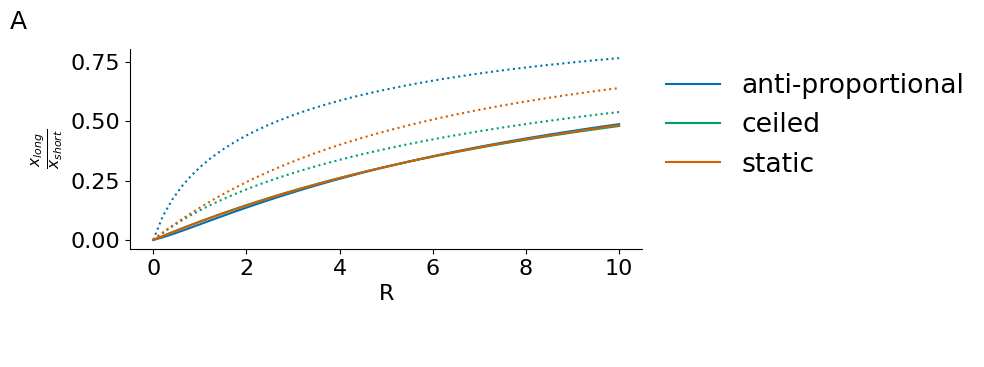

In [5]:
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, ys_bs[:,1], label = 'anti-proportional', color = palette[0])
ax.plot(Rs, ys_bs[:,0], color = palette[0], linestyle = ':')
ax.plot(Rs, ys_lr[:,1], label = 'ceiled', color = palette[1])
ax.plot(Rs, ys_lr[:,0], color = palette[1], linestyle = ':')
ax.plot(Rs, ys_sr[:,1], label = 'static', color = palette[2])
ax.plot(Rs, ys_sr[:,0], color = palette[2], linestyle = ':')
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
#changed to be the same as the Osterweil lab paper
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)
plt.show()


static beta


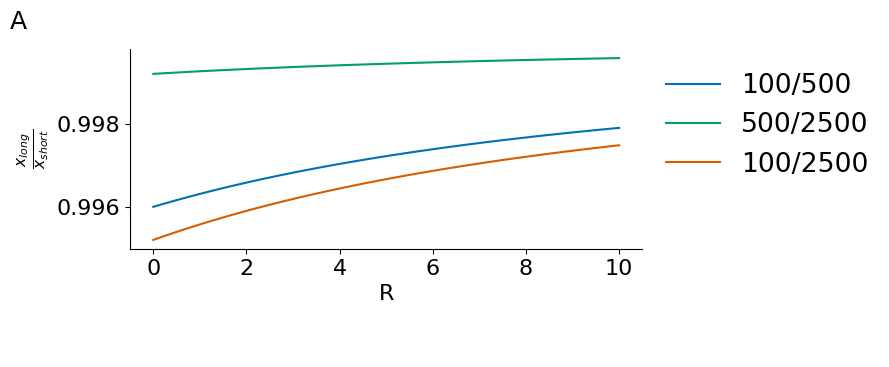

non-linear beta


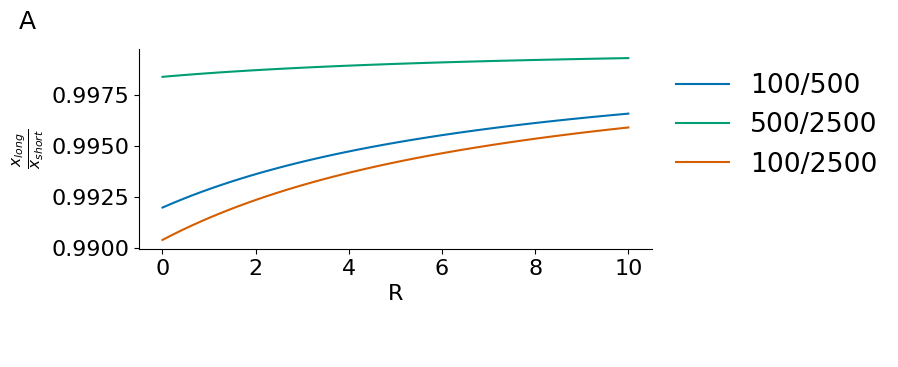

In [6]:
print('static beta')
ys_bs = np.zeros([Rs.shape[0], N])
ys_lr = np.zeros([Rs.shape[0], N])
ys_sr = np.zeros([Rs.shape[0], N])

parameters = dict()
parameters['β'] = β
parameters['α'] = α  #so initiation is the rate limiting step
parameters['δ'] = δ/l
parameters['γ'] = γ
parameters['l'] = l
parameters['Y_max'] = Ys


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    
    l = np.array([100,500])
    parameters['l'] = l
    parameters['δ'] = δ/l

    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_static, sim_time, dt) 
    ys_bs[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([500,2500])
    parameters['l'] = l
    parameters['δ'] = δ/l

    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_static, sim_time, dt) 
    ys_lr[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([100,2500])
    parameters['l'] = l
    parameters['δ'] = δ/l
    
    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_static, sim_time, dt) 
    ys_sr[r,:]= res[-1,1,:]#es[-1,2,:]

        
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, ys_bs[:,1]/ys_bs[:,0], label = '100/500', color = palette[0])
ax.plot(Rs, ys_lr[:,1]/ys_lr[:,0], label = '500/2500', color = palette[1])
ax.plot(Rs, ys_sr[:,1]/ys_sr[:,0], label = '100/2500', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
#changed to be the same as the Osterweil lab paper
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)
plt.show()



print('non-linear beta')

ys_bs = np.zeros([Rs.shape[0], N])
ys_lr = np.zeros([Rs.shape[0], N])
ys_sr = np.zeros([Rs.shape[0], N])

parameters = dict()
parameters['α'] = α
parameters['β'] = β
parameters['δ'] = δ/l
parameters['γ'] = γ
parameters['l'] = l
parameters['Y_max'] = Ys


for r in range(Rs.shape[0]):

    parameters['R'] = Rs[r]
    
    l = np.array([100,500])
    parameters['l'] = l
    parameters['δ'] = δ/l

    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_nonlin, sim_time, dt) 
    ys_bs[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([500,2500])
    parameters['l'] = l
    parameters['δ'] = δ/l 

    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_nonlin, sim_time, dt) 
    ys_lr[r,:]= res[-1,1,:]#res[-1,2,:]
    
    l = np.array([100,2500])
    parameters['l'] = l
    parameters['δ'] = δ/l
    
    res = simulation_wrapper(init_state,parameters,TASEP_assump, β_nonlin, sim_time, dt) 
    ys_sr[r,:]= res[-1,1,:]#res[-1,2,:]


        
layout = '''
    AA
    AA
    '''



fig = plt.figure(figsize=(8, 4))

height_ratios = [1,0.1]
width_ratios = [1,0.1]


specs, gs = panel_specs(layout, fig=fig)
gs.set_height_ratios(height_ratios)
gs.set_width_ratios(width_ratios)
gs.hspace=0.8
axes = {}
for letter in 'A':
    axes[letter] = ax = fig.add_subplot(specs[letter])
label_panels(axes, letters='A', postfix='', offset_left=1.2)
for a in list('A'):
    axes[a].set_axis_off()


ax = fig.add_subplot(gs[0,0])
ax.plot(Rs, ys_bs[:,1]/ys_bs[:,0], label = '100/500', color = palette[0])
ax.plot(Rs, ys_lr[:,1]/ys_lr[:,0], label = '500/2500', color = palette[1])
ax.plot(Rs, ys_sr[:,1]/ys_sr[:,0], label = '100/2500', color = palette[2])
ax.set_xlabel('R')
ax.set_ylabel('$\\frac{x_{long}}{x_{short}}$')
#changed to be the same as the Osterweil lab paper
ax.legend( bbox_to_anchor=(1.0, 1.0), loc='upper left',  frameon = False)
clear_axes(ax)
plt.show()
